📂 Upload your 'Queue_Dataset.csv' file


Saving Queue_Dataset.csv to Queue_Dataset (21).csv
✅ Loaded 156 records from Queue_Dataset (21).csv

🔄 DATA PREPROCESSING
✅ Preprocessing complete!

📊 DESCRIPTIVE STATISTICS
Total Records          : 156
Days Analyzed          : 2
Avg Waiting Time       : 0.09 min (5.5 sec)
Median Waiting Time    : 0.07 min (4.0 sec)
Max Waiting Time       : 0.43 min (26.0 sec)
Std Dev Waiting Time   : 0.10 min
Avg Service Duration   : 0.03 min (2.0 sec)
Min Service Duration   : 0.02 min (1.0 sec)
Max Service Duration   : 0.07 min (4.0 sec)

📊 BATCH STATISTICS

Batch 1 (08:30):
  Students     : 44
  Avg Wait     : 0.10 min (5.9 sec)
  Max Wait     : 0.30 min (18.0 sec)
  Avg Service  : 0.03 min (1.9 sec)

Batch 2 (13:30):
  Students     : 74
  Avg Wait     : 0.11 min (6.4 sec)
  Max Wait     : 0.43 min (26.0 sec)
  Avg Service  : 0.04 min (2.1 sec)

Batch 3 (16:30):
  Students     : 38
  Avg Wait     : 0.06 min (3.4 sec)
  Max Wait     : 0.17 min (10.0 sec)
  Avg Service  : 0.03 min (2.1 sec)

📊 SERVICE

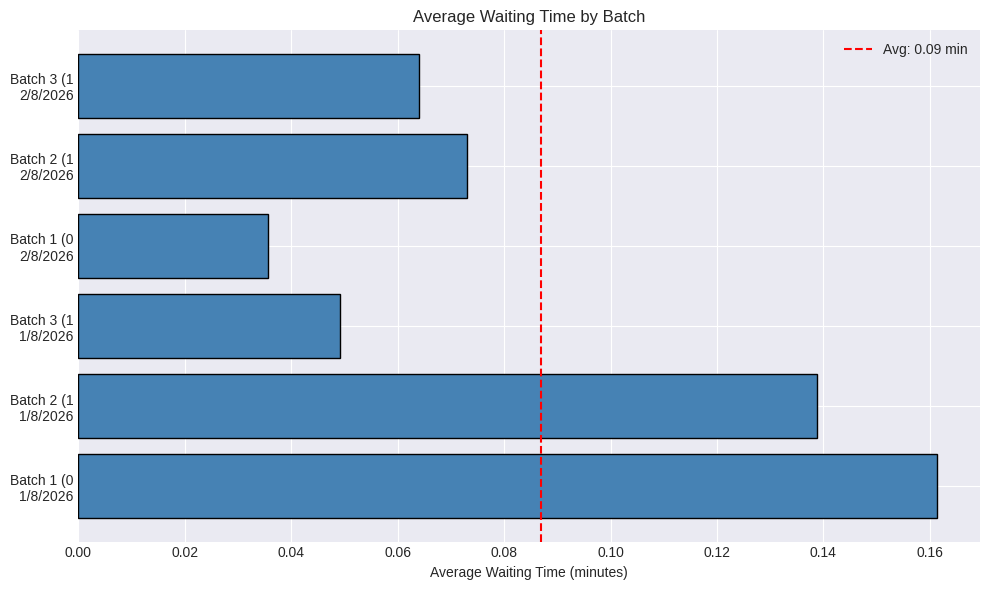

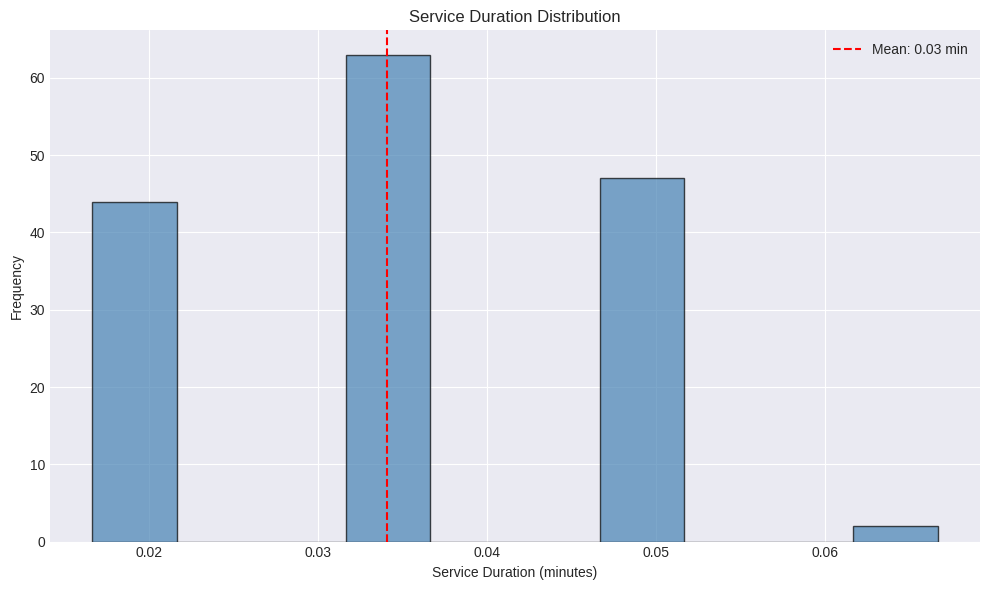

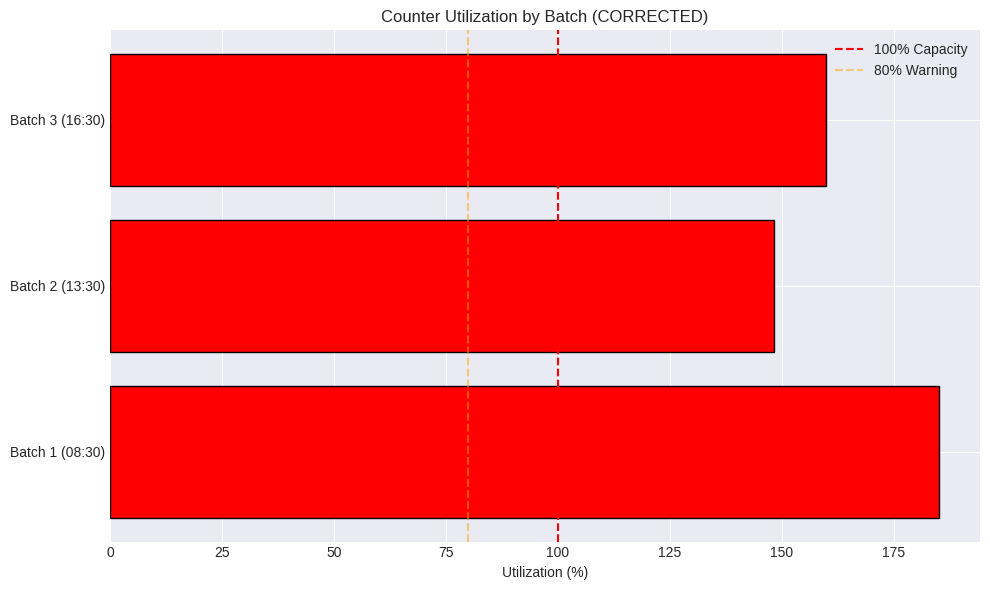

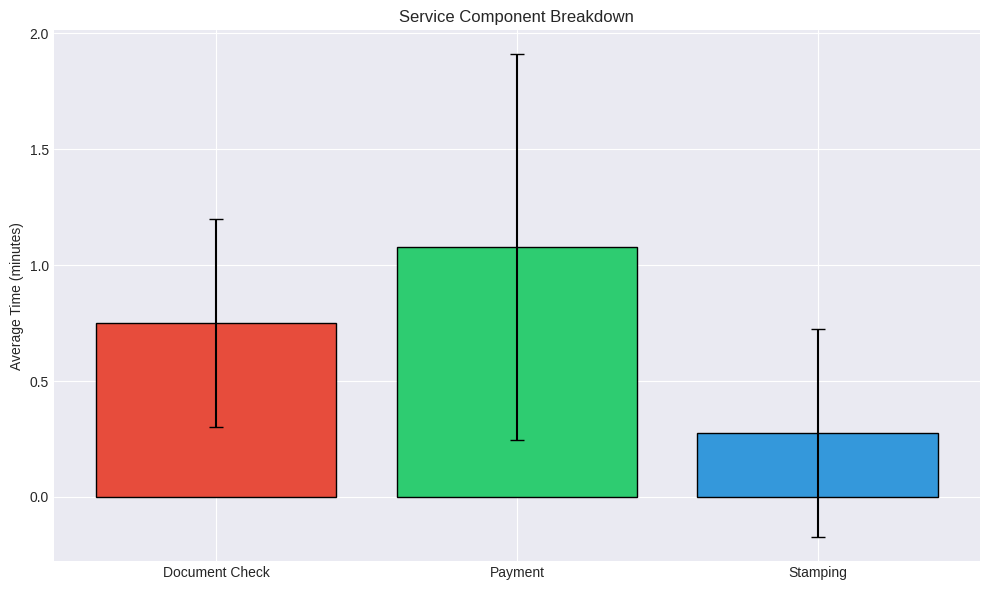

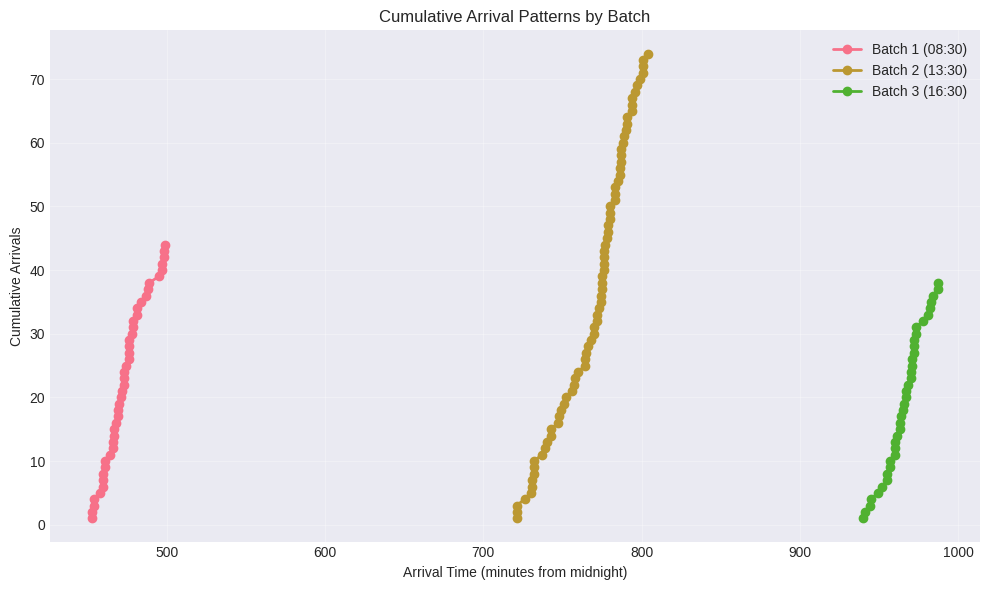

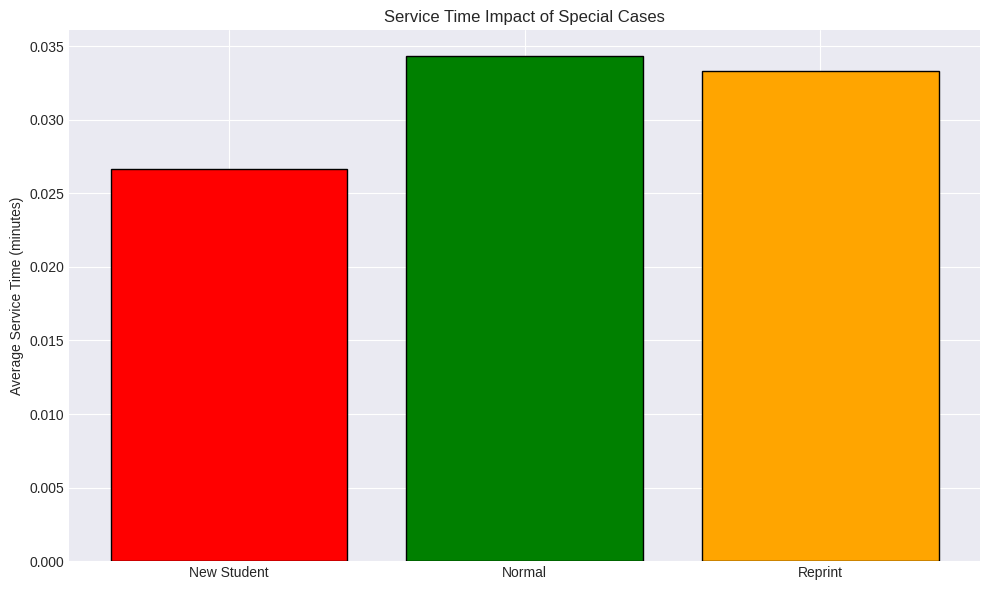


📋 FINAL SUMMARY

    ┌─────────────────────────────────────────────────────────────┐
    │   SAKURA INSTITUTE QUEUE ANALYSIS                          │
    ├─────────────────────────────────────────────────────────────┤
    │   Total Records         : 156                           │
    │   Days Analyzed         : 2             │
    │   Average Waiting Time  : 0.09 min │
    │   Max Waiting Time      : 0.43 min │
    │   Average Service Time  : 0.03 min │
    │   Service Rate (μ)      : 0.476 students/min             │
    ├─────────────────────────────────────────────────────────────┤
    │   Batch 1 (08:30)       :  44 students │
    │   Batch 2 (13:30)       :  74 students │
    │   Batch 3 (16:30)       :  38 students │
    └─────────────────────────────────────────────────────────────┘
    
⚠️⚠️⚠️  WARNING: SYSTEM IS UNSTABLE! ⚠️⚠️⚠️
   - Batch 1 (08:30): ρ = 1.850 (> 1)
   - Batch 2 (13:30): ρ = 1.482 (> 1)
   - Batch 3 (16:30): ρ = 1.598 (> 1)

💡 RECOMMENDATION: A second count

In [26]:
# ============================================================
# Step 1: Import Libraries
# ============================================================

from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')

# ============================================================
# Step 2: Upload File
# ============================================================

print("="*60)
print("📂 Upload your 'Queue_Dataset.csv' file")
print("="*60)

uploaded = files.upload()

if len(uploaded) == 0:
    print("❌ No file uploaded.")
else:
    filename = list(uploaded.keys())[0]
    df = pd.read_csv(filename)
    print(f"✅ Loaded {len(df)} records from {filename}")

    # ============================================================
    # Step 3: Data Preprocessing
    # ============================================================

    print("\n" + "="*60)
    print("🔄 DATA PREPROCESSING")
    print("="*60)

    def to_minutes(time_str):
        """Convert HH:MM to minutes from midnight"""
        if isinstance(time_str, str) and ':' in time_str:
            try:
                h, m = map(int, time_str.split(':'))
                return h * 60 + m
            except:
                return None
        return None

    def mmss_to_decimal(time_str):
        """Convert MM:SS to decimal minutes (e.g., 0:26 -> 0.433 min)"""
        if isinstance(time_str, str) and ':' in time_str:
            try:
                parts = time_str.split(':')
                if len(parts) == 2:
                    m = int(parts[0])
                    s = int(parts[1])
                    return m + s/60.0
                else:
                    return None
            except:
                return None
        return None

    # Convert time columns (HH:MM -> minutes from midnight)
    for col in ['Arrival_Time', 'Service_Start_Time', 'Document_Check_End_Time',
                'Payment_Time', 'Service_End_Time']:
        if col in df.columns:
            df[col + '_mins'] = df[col].apply(to_minutes)

    # Convert duration columns (MM:SS -> decimal minutes)
    df['Waiting_Time_min'] = df['Waiting_Time'].apply(mmss_to_decimal)
    df['Service_Duration_min'] = df['Service_Duration'].apply(mmss_to_decimal)
    df['Total_Process_Time_min'] = df['Total_Process_Time'].apply(mmss_to_decimal)

    # Calculate service components (in minutes from timestamps)
    df['T_document'] = df['Document_Check_End_Time_mins'] - df['Service_Start_Time_mins']
    df['T_payment'] = df['Payment_Time_mins'] - df['Document_Check_End_Time_mins']
    df['T_stamping'] = df['Service_End_Time_mins'] - df['Payment_Time_mins']

    # Calculate total service time from components (CORRECTED)
    df['Total_Service_Time_components'] = df['T_document'] + df['T_payment'] + df['T_stamping']

    # Extract batch from Remarks
    def get_batch(remarks):
        if isinstance(remarks, str):
            if 'Batch 1' in remarks:
                return 'Batch 1 (08:30)'
            elif 'Batch 2' in remarks:
                return 'Batch 2 (13:30)'
            elif 'Batch 3' in remarks:
                return 'Batch 3 (16:30)'
        return 'Unknown'

    df['Batch'] = df['Remarks'].apply(get_batch)

    # Extract special cases
    def get_special(remarks):
        if isinstance(remarks, str):
            if 'Reprint' in remarks:
                return 'Reprint'
            elif 'New student' in remarks:
                return 'New Student'
        return 'Normal'

    df['Special_Case'] = df['Remarks'].apply(get_special)

    print("✅ Preprocessing complete!")

    # ============================================================
    # Step 4: Descriptive Statistics
    # ============================================================

    print("\n" + "="*60)
    print("📊 DESCRIPTIVE STATISTICS")
    print("="*60)

    print(f"Total Records          : {len(df)}")
    print(f"Days Analyzed          : {df['Date'].nunique()}")
    print(f"Avg Waiting Time       : {df['Waiting_Time_min'].mean():.2f} min ({df['Waiting_Time_min'].mean()*60:.1f} sec)")
    print(f"Median Waiting Time    : {df['Waiting_Time_min'].median():.2f} min ({df['Waiting_Time_min'].median()*60:.1f} sec)")
    print(f"Max Waiting Time       : {df['Waiting_Time_min'].max():.2f} min ({df['Waiting_Time_min'].max()*60:.1f} sec)")
    print(f"Std Dev Waiting Time   : {df['Waiting_Time_min'].std():.2f} min")
    print(f"Avg Service Duration   : {df['Service_Duration_min'].mean():.2f} min ({df['Service_Duration_min'].mean()*60:.1f} sec)")
    print(f"Min Service Duration   : {df['Service_Duration_min'].min():.2f} min ({df['Service_Duration_min'].min()*60:.1f} sec)")
    print(f"Max Service Duration   : {df['Service_Duration_min'].max():.2f} min ({df['Service_Duration_min'].max()*60:.1f} sec)")

    # ============================================================
    # Step 5: Batch Statistics
    # ============================================================

    print("\n" + "="*60)
    print("📊 BATCH STATISTICS")
    print("="*60)

    batch_windows = {
        'Batch 1 (08:30)': 50,
        'Batch 2 (13:30)': 105,
        'Batch 3 (16:30)': 50,
    }

    for batch in ['Batch 1 (08:30)', 'Batch 2 (13:30)', 'Batch 3 (16:30)']:
        bdf = df[df['Batch'] == batch]
        if len(bdf) > 0:
            print(f"\n{batch}:")
            print(f"  Students     : {len(bdf)}")
            print(f"  Avg Wait     : {bdf['Waiting_Time_min'].mean():.2f} min ({bdf['Waiting_Time_min'].mean()*60:.1f} sec)")
            print(f"  Max Wait     : {bdf['Waiting_Time_min'].max():.2f} min ({bdf['Waiting_Time_min'].max()*60:.1f} sec)")
            print(f"  Avg Service  : {bdf['Service_Duration_min'].mean():.2f} min ({bdf['Service_Duration_min'].mean()*60:.1f} sec)")

    # ============================================================
    # Step 6: Service Components
    # ============================================================

    print("\n" + "="*60)
    print("📊 SERVICE COMPONENTS")
    print("="*60)

    print(f"Document Check  : {df['T_document'].mean():.2f} min ({df['T_document'].mean()*60:.1f} sec)")
    print(f"Payment         : {df['T_payment'].mean():.2f} min ({df['T_payment'].mean()*60:.1f} sec)")
    print(f"Stamping        : {df['T_stamping'].mean():.2f} min ({df['T_stamping'].mean()*60:.1f} sec)")
    print(f"Total Service   : {df['Total_Service_Time_components'].mean():.2f} min ({df['Total_Service_Time_components'].mean()*60:.1f} sec)")

    # ============================================================
    # Step 7: Special Cases
    # ============================================================

    print("\n" + "="*60)
    print("📊 SPECIAL CASES")
    print("="*60)

    for case in ['Normal', 'Reprint', 'New Student']:
        cdf = df[df['Special_Case'] == case]
        if len(cdf) > 0:
            print(f"{case:<12}: {len(cdf):>3} students, Avg Service: {cdf['Service_Duration_min'].mean():.2f} min ({cdf['Service_Duration_min'].mean()*60:.1f} sec)")

    # ============================================================
    # Step 8: Utilization & Throughput
    # ============================================================

    print("\n" + "="*60)
    print("📊 UTILIZATION & THROUGHPUT")
    print("="*60)
    print("⚠️ Using component-based service time (Total Service = 2.11 min)")

    # Calculate average service time from components
    avg_service_time = df['Total_Service_Time_components'].mean()
    mu = 1 / avg_service_time

    print(f"\nAverage Service Time (from components): {avg_service_time:.2f} min")
    print(f"Service Rate (μ): {mu:.3f} students/min")

    for batch in ['Batch 1 (08:30)', 'Batch 2 (13:30)', 'Batch 3 (16:30)']:
        bdf = df[df['Batch'] == batch]
        if len(bdf) > 0:
            window = batch_windows.get(batch, 60)
            lambda_rate = len(bdf) / window
            rho = lambda_rate / mu
            status = "⚠️ UNSTABLE" if rho > 1 else "✅ Stable"
            print(f"\n{batch}:")
            print(f"  λ (arrival rate) : {lambda_rate:.3f} students/min")
            print(f"  μ (service rate) : {mu:.3f} students/min")
            print(f"  ρ (utilization)  : {rho:.3f} ({status})")

    # ============================================================
    # Step 9: M/M/1 Predictions
    # ============================================================

    print("\n" + "="*60)
    print("📊 M/M/1 MODEL PREDICTIONS")
    print("="*60)

    for batch in ['Batch 1 (08:30)', 'Batch 2 (13:30)', 'Batch 3 (16:30)']:
        bdf = df[df['Batch'] == batch]
        if len(bdf) > 0:
            window = batch_windows.get(batch, 60)
            lambda_rate = len(bdf) / window
            rho = lambda_rate / mu

            if rho < 1:
                Lq = (rho**2) / (1 - rho)
                Wq = rho / (mu * (1 - rho))
                W = 1 / (mu * (1 - rho))
                print(f"\n{batch}:")
                print(f"  Lq (queue length) : {Lq:.2f} students")
                print(f"  Wq (wait time)    : {Wq:.2f} min")
                print(f"  W (system time)   : {W:.2f} min")
            else:
                print(f"\n{batch}: ⚠️ UNSTABLE (ρ = {rho:.3f} > 1)")
                print(f"  → Queue grows indefinitely!")
                print(f"  → A second counter is REQUIRED!")

    # ============================================================
    # Step 10: Visualizations
    # ============================================================

    print("\n" + "="*60)
    print("📊 GENERATING VISUALIZATIONS")
    print("="*60)

    # Graph 1: Waiting Time by Batch
    plt.figure(figsize=(10, 6))
    wait_data = df.groupby(['Date', 'Batch'])['Waiting_Time_min'].mean().reset_index()
    labels = [f"{row['Batch'][:10]}\n{row['Date']}" for _, row in wait_data.iterrows()]
    plt.barh(labels, wait_data['Waiting_Time_min'], color='steelblue', edgecolor='black')
    plt.axvline(x=wait_data['Waiting_Time_min'].mean(), color='red', linestyle='--',
                label=f"Avg: {wait_data['Waiting_Time_min'].mean():.2f} min")
    plt.xlabel('Average Waiting Time (minutes)')
    plt.title('Average Waiting Time by Batch')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Graph 2: Service Duration Distribution
    plt.figure(figsize=(10, 6))
    plt.hist(df['Service_Duration_min'], bins=10, edgecolor='black', color='steelblue', alpha=0.7)
    plt.axvline(df['Service_Duration_min'].mean(), color='red', linestyle='--',
                label=f"Mean: {df['Service_Duration_min'].mean():.2f} min")
    plt.xlabel('Service Duration (minutes)')
    plt.ylabel('Frequency')
    plt.title('Service Duration Distribution')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Graph 3: Counter Utilization (CORRECTED)
    plt.figure(figsize=(10, 6))
    util_data = []
    for batch in ['Batch 1 (08:30)', 'Batch 2 (13:30)', 'Batch 3 (16:30)']:
        bdf = df[df['Batch'] == batch]
        if len(bdf) > 0:
            window = batch_windows.get(batch, 60)
            lambda_rate = len(bdf) / window
            rho = lambda_rate / mu
            util_data.append({'Batch': batch, 'Utilization': rho * 100})

    util_df = pd.DataFrame(util_data)
    colors = ['red' if u > 100 else 'orange' if u > 80 else 'green' for u in util_df['Utilization']]
    plt.barh(util_df['Batch'], util_df['Utilization'], color=colors, edgecolor='black')
    plt.axvline(x=100, color='red', linestyle='--', label='100% Capacity')
    plt.axvline(x=80, color='orange', linestyle='--', alpha=0.5, label='80% Warning')
    plt.xlabel('Utilization (%)')
    plt.title('Counter Utilization by Batch (CORRECTED)')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Graph 4: Service Component Breakdown
    plt.figure(figsize=(10, 6))
    components = ['Document Check', 'Payment', 'Stamping']
    values = [df['T_document'].mean(), df['T_payment'].mean(), df['T_stamping'].mean()]
    stds = [df['T_document'].std(), df['T_payment'].std(), df['T_stamping'].std()]
    colors = ['#e74c3c', '#2ecc71', '#3498db']
    plt.bar(components, values, color=colors, yerr=stds, capsize=5, edgecolor='black')
    plt.ylabel('Average Time (minutes)')
    plt.title('Service Component Breakdown')
    plt.tight_layout()
    plt.show()

    # Graph 5: Cumulative Arrival Patterns
    plt.figure(figsize=(10, 6))
    for batch in ['Batch 1 (08:30)', 'Batch 2 (13:30)', 'Batch 3 (16:30)']:
        bdf = df[df['Batch'] == batch]
        if len(bdf) > 0:
            times = sorted(bdf['Arrival_Time_mins'].dropna())
            cum = range(1, len(times) + 1)
            plt.plot(times, cum, 'o-', label=batch, markersize=6, linewidth=2)
    plt.xlabel('Arrival Time (minutes from midnight)')
    plt.ylabel('Cumulative Arrivals')
    plt.title('Cumulative Arrival Patterns by Batch')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Graph 6: Special Cases Impact
    plt.figure(figsize=(10, 6))
    special_avg = df.groupby('Special_Case')['Service_Duration_min'].mean().reset_index()
    colors = ['green' if c == 'Normal' else 'orange' if c == 'Reprint' else 'red' for c in special_avg['Special_Case']]
    plt.bar(special_avg['Special_Case'], special_avg['Service_Duration_min'], color=colors, edgecolor='black')
    plt.ylabel('Average Service Time (minutes)')
    plt.title('Service Time Impact of Special Cases')
    plt.tight_layout()
    plt.show()

    # ============================================================
    # Step 11: Final Summary
    # ============================================================

    print("\n" + "="*60)
    print("📋 FINAL SUMMARY")
    print("="*60)

    # Calculate unstable batches
    unstable_batches = []
    for batch in ['Batch 1 (08:30)', 'Batch 2 (13:30)', 'Batch 3 (16:30)']:
        bdf = df[df['Batch'] == batch]
        if len(bdf) > 0:
            window = batch_windows.get(batch, 60)
            lambda_rate = len(bdf) / window
            rho = lambda_rate / mu
            if rho > 1:
                unstable_batches.append((batch, rho))

    print(f"""
    ┌─────────────────────────────────────────────────────────────┐
    │   SAKURA INSTITUTE QUEUE ANALYSIS                          │
    ├─────────────────────────────────────────────────────────────┤
    │   Total Records         : {len(df)}                           │
    │   Days Analyzed         : {df['Date'].nunique()}             │
    │   Average Waiting Time  : {df['Waiting_Time_min'].mean():.2f} min │
    │   Max Waiting Time      : {df['Waiting_Time_min'].max():.2f} min │
    │   Average Service Time  : {df['Service_Duration_min'].mean():.2f} min │
    │   Service Rate (μ)      : {mu:.3f} students/min             │
    ├─────────────────────────────────────────────────────────────┤
    │   Batch 1 (08:30)       : {len(df[df['Batch']=='Batch 1 (08:30)']):>3} students │
    │   Batch 2 (13:30)       : {len(df[df['Batch']=='Batch 2 (13:30)']):>3} students │
    │   Batch 3 (16:30)       : {len(df[df['Batch']=='Batch 3 (16:30)']):>3} students │
    └─────────────────────────────────────────────────────────────┘
    """)

    if unstable_batches:
        print("⚠️⚠️⚠️  WARNING: SYSTEM IS UNSTABLE! ⚠️⚠️⚠️")
        for batch, rho in unstable_batches:
            print(f"   - {batch}: ρ = {rho:.3f} (> 1)")
        print("\n💡 RECOMMENDATION: A second counter is REQUIRED!")
        print("   The current single-counter system cannot handle the arrival rate.")
    else:
        print("✅ All batches are stable.")

    print("\n" + "="*60)
    print("✅ ANALYSIS COMPLETE!")
    print("="*60)